In [1]:
import os
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

In [ ]:
RAW_WIDE_PATH = "../data/raw/crypto_yahoo_1d_2015-01-01_to_2025-12-19_RAW_WIDE.csv"
PROCESSED_DIR = "../data/processed"
os.makedirs(PROCESSED_DIR, exist_ok=True)

# Kolom standar
DATE_COL = "Date"
TICKER_COL = "Ticker"
TARGET_COL = "Close"

TICKERS = ["BTC-USD", "ETH-USD", "BNB-USD"]

INTERSECTION_START = "2017-11-09"

LOOKBACK = 60
HORIZONS = [1]

TRAIN_RATIO = 0.70
VAL_RATIO   = 0.15
TEST_RATIO  = 0.15

In [6]:
# CELL 3 — Load RAW WIDE (CSV MultiIndex)
df_wide = pd.read_csv(
    RAW_WIDE_PATH,
    header=[0, 1],     # karena CSV dari yfinance punya 2-level header
    index_col=0       # kolom pertama adalah Date
)

# pastikan index datetime
df_wide.index = pd.to_datetime(df_wide.index, errors="coerce")

# buang baris dengan index NaT (jika ada)
df_wide = df_wide[~df_wide.index.isna()].copy()

print("WIDE shape:", df_wide.shape)
df_wide.tail()

WIDE shape: (4005, 18)


Ticker           BTC-USD                                            \
Price               Open          High           Low         Close   
Date                                                                 
2025-12-14  90296.437500  90498.109375  87634.937500  88175.179688   
2025-12-15  88171.078125  89983.921875  85304.078125  86419.781250   
2025-12-16  86424.406250  88170.093750  85381.687500  87843.984375   
2025-12-17  87847.617188  90264.570312  85316.265625  86143.757812   
2025-12-18  86144.367188  89412.664062  84436.312500  85462.507812   

Ticker                                     ETH-USD                            \
Price          Adj Close       Volume         Open         High          Low   
Date                                                                           
2025-12-14  88175.179688  50465972205  3116.743896  3128.622803  3034.692627   
2025-12-15  86419.781250  45559514323  3060.481445  3175.118164  2899.685791   
2025-12-16  87843.984375  41262178223  2964.379639  2978.921387  2890.011719   
2025-12-17  86143.757812  44243392914  2964.019531  3025.815430  2791.333984   
2025-12-18  85462.507812  52667115348  2831.488281  2994.552734  2777.119629   

Ticker                                                 BNB-USD              \
Price             Close    Adj Close        Volume        Open        High   
Date                                                                         
2025-12-14  3060.594727  3060.594727  1.561954e+10  897.435791  899.217651   
2025-12-15  2964.183105  2964.183105  2.876598e+10  877.789246  894.205261   
2025-12-16  2964.180908  2964.180908  2.270919e+10  858.545898  877.613098   
2025-12-17  2831.403564  2831.403564  2.615983e+10  874.905518  875.110840   
2025-12-18  2827.069092  2827.069092  2.919418e+10  842.931274  850.898376   

Ticker                                                        
Price              Low       Close   Adj Close        Volume  
Date                                                          
2025-12-14  874.129639  877.806885  877.806885  1.640570e+09  
2025-12-15  843.767883  858.545105  858.545105  2.222158e+09  
2025-12-16  851.367615  874.899048  874.899048  2.379705e+09  
2025-12-17  834.851685  842.930176  842.930176  2.968394e+09  
2025-12-18  819.983826  829.301147  829.301147  3.195634e+09

In [7]:
# CELL 4 — Convert WIDE -> LONG (multi-ticker ke long format)
# df_wide columns: level0=ticker, level1=feature (Open/High/Low/Close/Adj Close/Volume)
df_long = (
    df_wide.stack(level=0)
        .rename_axis([DATE_COL, TICKER_COL])
        .reset_index()
)

df_long[DATE_COL] = pd.to_datetime(df_long[DATE_COL], errors="coerce")
df_long = df_long.dropna(subset=[DATE_COL]).copy()

# Filter tickers (jaga-jaga)
df_long = df_long[df_long[TICKER_COL].isin(TICKERS)].copy()

df_long = df_long.sort_values([TICKER_COL, DATE_COL]).reset_index(drop=True)

print("LONG shape:", df_long.shape)
df_long.head()


LONG shape: (9929, 8)


C:\Users\asusg\AppData\Local\Temp\ipykernel_23600\1992647031.py:4: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  df_wide.stack(level=0)


Price,Date,Ticker,Open,High,Low,Close,Adj Close,Volume
0,2017-11-09,BNB-USD,2.05314,2.17423,1.89394,1.99077,1.99077,19192200.0
1,2017-11-10,BNB-USD,2.00773,2.06947,1.64478,1.79684,1.79684,11155000.0
2,2017-11-11,BNB-USD,1.78628,1.91775,1.61429,1.67047,1.67047,8178150.0
3,2017-11-12,BNB-USD,1.66889,1.67280,1.46256,1.51969,1.51969,15298700.0
4,2017-11-13,BNB-USD,1.52601,1.73502,1.51760,1.68662,1.68662,12238800.0


In [8]:
# CELL 5 — Cek Close vs Adj Close (lalu drop Adj Close jika identik)
if "Adj Close" in df_long.columns:
    close_num = pd.to_numeric(df_long["Close"], errors="coerce")
    adj_num   = pd.to_numeric(df_long["Adj Close"], errors="coerce")
    diff = (adj_num - close_num).abs()

    n_diff = int((diff > 0).sum())
    print("Adj Close vs Close:")
    print("  count diff>0:", n_diff)
    print("  max abs diff:", float(diff.max()))
    print("  mean abs diff:", float(diff.mean()))

    if n_diff == 0:
        df_long = df_long.drop(columns=["Adj Close"])
        print("Adj Close identik dengan Close → kolom Adj Close dihapus.")
    else:
        print("WARNING: Adj Close berbeda dari Close. Kolom tidak dihapus.")
        display(df_long.loc[diff > 0, [DATE_COL, TICKER_COL, "Close", "Adj Close"]].head(10))
else:
    print("Kolom Adj Close tidak ada. Lanjut.")

Adj Close vs Close:
  count diff>0: 0
  max abs diff: 0.0
  mean abs diff: 0.0
Adj Close identik dengan Close → kolom Adj Close dihapus.


In [9]:
# CELL 6 — Intersection (penyelarasan rentang waktu)
start_dt = pd.to_datetime(INTERSECTION_START)

# common_end agar semua ticker benar-benar overlap sampai tanggal yang sama
common_end = df_long.groupby(TICKER_COL)[DATE_COL].max().min()

df_int = df_long[(df_long[DATE_COL] >= start_dt) & (df_long[DATE_COL] <= common_end)].copy()
df_int = df_int.sort_values([TICKER_COL, DATE_COL]).reset_index(drop=True)

print("Intersection range:")
print("  start:", df_int[DATE_COL].min().date())
print("  end  :", df_int[DATE_COL].max().date())
display(df_int.groupby(TICKER_COL)[DATE_COL].agg(["min", "max", "count"]))

Intersection range:
  start: 2017-11-09
  end  : 2025-12-18


,min,max,count
Ticker,,,
BNB-USD,2017-11-09,2025-12-18,2962
BTC-USD,2017-11-09,2025-12-18,2962
ETH-USD,2017-11-09,2025-12-18,2962


In [11]:
# CELL 7 — Basic checks (missing, duplicate)
print("Missing Close:", int(df_int["Close"].isna().sum()))
print("Duplicate (Ticker, Date):", int(df_int.duplicated([TICKER_COL, DATE_COL]).sum()))

# drop NA close
df_int = df_int.dropna(subset=["Close"]).copy()

# Cek missing DATE per ticker (BTC, ETH, BNB)
print("\nMissing dates per ticker:")

for t in TICKERS:
    dft = df_int[df_int[TICKER_COL] == t].sort_values(DATE_COL)

    full_range = pd.date_range(
        start=dft[DATE_COL].min(),
        end=dft[DATE_COL].max(),
        freq="D"
    )

    missing_dates = full_range.difference(dft[DATE_COL])

    print(f"{t}: {len(missing_dates)} missing dates")

    # opsional: tampilkan contoh (biar tidak spam)
    if len(missing_dates) > 0:
        print("  sample:", missing_dates[:5].date.tolist())

Missing Close: 0
Duplicate (Ticker, Date): 0

Missing dates per ticker:
BTC-USD: 0 missing dates
ETH-USD: 0 missing dates
BNB-USD: 0 missing dates


In [12]:
print("Descriptive statistics (Close price):\n")

for t in TICKERS:
    dft = df_int[df_int[TICKER_COL] == t]
    desc = dft["Close"].describe(percentiles=[0.01, 0.05, 0.95, 0.99])
    print(f"\n{t}")
    print(desc)

Descriptive statistics (Close price):


BTC-USD
count      2962.000000
mean      36604.823522
std       31992.892461
min        3236.761719
1%         3603.751636
5%         5205.236353
50%       26812.481445
95%      106044.837109
99%      117563.359531
max      124752.531250
Name: Close, dtype: float64

ETH-USD
count    2962.000000
mean     1679.151977
std      1295.988118
min        84.308296
1%        110.345992
5%        139.436793
50%      1638.707336
95%      3933.665125
99%      4517.824551
max      4831.348633
Name: Close, dtype: float64

BNB-USD
count    2962.000000
mean      284.529250
std       273.482152
min         1.510360
1%          2.655765
5%          8.783326
50%       261.493820
95%       757.069806
99%      1071.996147
max      1310.214355
Name: Close, dtype: float64


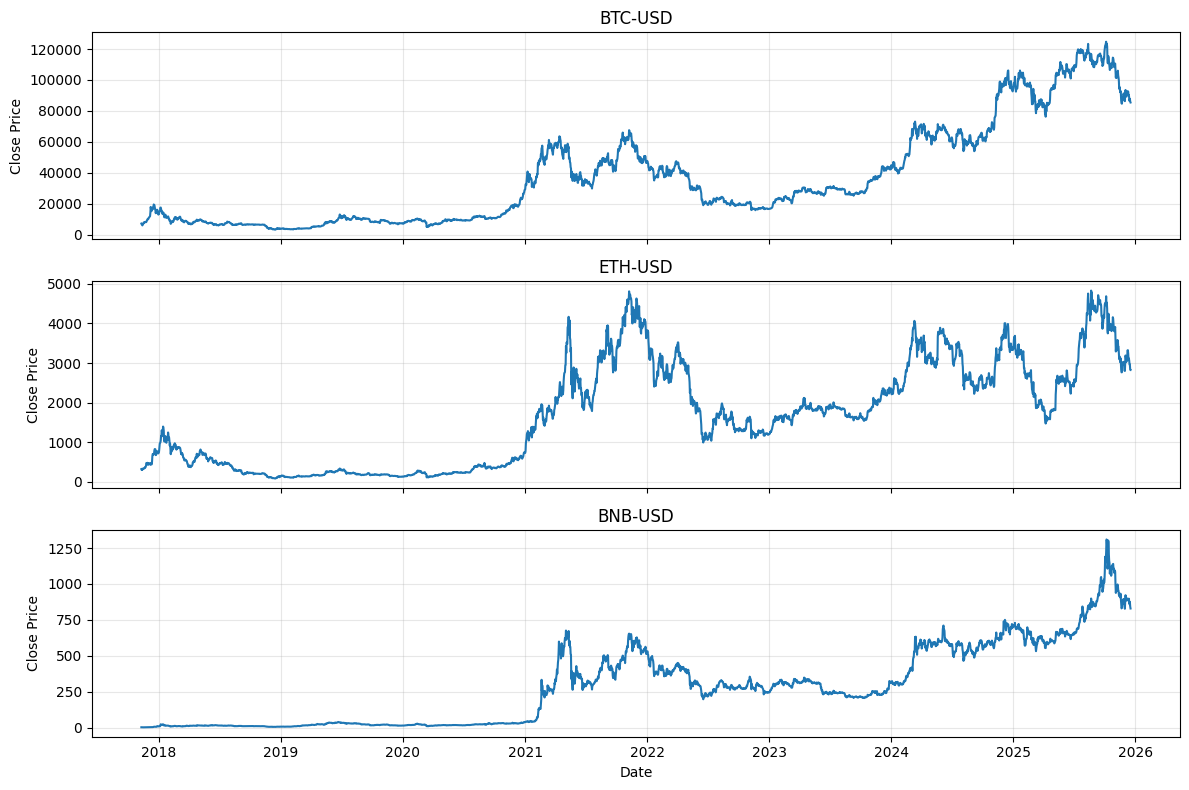

In [ ]:
# Plot terpisah per aset (outlier visualization)
import matplotlib.pyplot as plt

fig, axes = plt.subplots(len(TICKERS), 1, figsize=(12, 8), sharex=True)

for ax, t in zip(axes, TICKERS):
    dft = df_int[df_int[TICKER_COL] == t]
    ax.plot(dft[DATE_COL], dft["Close"])
    ax.set_title(t)
    ax.set_ylabel("Close Price")
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Date")
plt.tight_layout()
plt.show()

In [22]:
# CELL 8 — Save PROCESSED LONG (untuk TimeGPT) sebelum normalisasi & windowing
processed_long_path = os.path.join(
    PROCESSED_DIR,
    f"crypto_yahoo_1d_intersection_{INTERSECTION_START}_to_{df_int[DATE_COL].max().date()}_LONG.csv"
)

df_timegpt = df_int[[DATE_COL, TICKER_COL, TARGET_COL]].copy()
df_timegpt.to_csv(processed_long_path, index=False)

print("Saved PROCESSED LONG (TimeGPT):", processed_long_path)
df_timegpt.head()

Saved PROCESSED LONG (TimeGPT): ../data/processed\crypto_yahoo_1d_intersection_2017-11-09_to_2025-12-18_LONG.csv


Price,Date,Ticker,Close
0,2017-11-09,BNB-USD,1.99077
1,2017-11-10,BNB-USD,1.79684
2,2017-11-11,BNB-USD,1.67047
3,2017-11-12,BNB-USD,1.51969
4,2017-11-13,BNB-USD,1.68662


In [ ]:
# CELL 9 — Windowing helpers
def make_window_data(series_2d, lookback, horizon):
    # series_2d: (n, 1)
    X, y = [], []
    n = len(series_2d)
    for i in range(n - lookback - horizon + 1):
        X.append(series_2d[i:i+lookback])
        y.append(series_2d[i+lookback+horizon-1, 0])
    return np.array(X, dtype=float), np.array(y, dtype=float)

def split_time_series(X, y, train_ratio=0.7, val_ratio=0.15):
    n = len(X)
    n_train = int(n * train_ratio)
    n_val = int(n * val_ratio)

    X_train, y_train = X[:n_train], y[:n_train]
    X_val, y_val     = X[n_train:n_train+n_val], y[n_train:n_train+n_val]
    X_test, y_test   = X[n_train+n_val:], y[n_train+n_val:]
    return X_train, y_train, X_val, y_val, X_test, y_test

In [24]:
# CELL 10 — Build LSTM datasets (.npz) per ticker & horizon (normalisasi + windowing + split)
OUT_DIR = os.path.join(PROCESSED_DIR, f"lstm_close_L{LOOKBACK}_start{INTERSECTION_START}")
os.makedirs(OUT_DIR, exist_ok=True)

for t in TICKERS:
    dft = df_int[df_int[TICKER_COL] == t].copy().sort_values(DATE_COL)

    close = pd.to_numeric(dft["Close"], errors="coerce").dropna().values.reshape(-1, 1)

    for H in HORIZONS:
        X, y = make_window_data(close, LOOKBACK, H)

        X_train, y_train, X_val, y_val, X_test, y_test = split_time_series(
            X, y, TRAIN_RATIO, VAL_RATIO
        )

        scaler = StandardScaler()
        X_train_s = scaler.fit_transform(X_train.reshape(-1, 1)).reshape(X_train.shape)
        X_val_s   = scaler.transform(X_val.reshape(-1, 1)).reshape(X_val.shape)
        X_test_s  = scaler.transform(X_test.reshape(-1, 1)).reshape(X_test.shape)

        out_path = os.path.join(OUT_DIR, f"{t}_Close_L{LOOKBACK}_H{H}.npz")
        np.savez_compressed(
            out_path,
            X_train=X_train_s, y_train=y_train,
            X_val=X_val_s,     y_val=y_val,
            X_test=X_test_s,   y_test=y_test,
            scaler_mean=scaler.mean_,
            scaler_scale=scaler.scale_
        )

        print(f"Saved: {out_path} | X_train={X_train_s.shape} X_test={X_test_s.shape}")

Saved: ../data/processed\lstm_close_L60_start2017-11-09\BTC-USD_Close_L60_H1.npz | X_train=(2031, 60, 1) X_test=(436, 60, 1)
Saved: ../data/processed\lstm_close_L60_start2017-11-09\ETH-USD_Close_L60_H1.npz | X_train=(2031, 60, 1) X_test=(436, 60, 1)
Saved: ../data/processed\lstm_close_L60_start2017-11-09\BNB-USD_Close_L60_H1.npz | X_train=(2031, 60, 1) X_test=(436, 60, 1)
